# Évaluation hold-out (LI-Medium) — Projet AML

Mêmes livrables que `metrics_evaluation.ipynb` (phase E train), pour le **test final** :

- tableaux CSV + `gnn_*_holdout_metrics.json`
- barres / radar / grille de métriques
- courbes Precision-Recall, matrices de confusion, distributions de scores
- comparaison **train (test LI-Small) vs hold-out (LI-Medium)**
- référence convergence entraînement (LI-Small)

> **Prérequis** : `python scripts/07_eval_holdout.py` puis `python scripts/09_visualize_holdout.py`

In [1]:
from pathlib import Path
import sys
from IPython.display import Image, display, Markdown

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src" / "config.py").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src import config
from src.evaluation.holdout_viz import holdout_metrics_dataframe, export_holdout_visualizations

config.set_data_profile("unknown")
RESULTS_DIR = config.RESULTS_DIR
print("Résultats hold-out :", RESULTS_DIR)

Résultats hold-out : C:\Users\MASTER DATA&IA\Desktop\YNOV\Projet - Connect AI\Project\data\unknown_data\results


In [2]:
# Régénérer toutes les figures (décommenter si besoin)
# export_holdout_visualizations()

In [3]:
df = holdout_metrics_dataframe()
display(df)

,model,split,split_label,best_epoch,pr_auc,recall,precision,f1,loss,n_samples,n_fraud
0,hetero,holdout,Hold-out (LI-Medium),40,0.594704,0.699271,0.543696,0.611747,0.303893,200000,16041
1,sage,holdout,Hold-out (LI-Medium),40,0.228645,0.780874,0.133487,0.227998,0.630870,200000,16041
2,gat,holdout,Hold-out (LI-Medium),3,0.149669,0.643414,0.114299,0.194115,0.686501,200000,16041


## Figures (`data/unknown_data/results/`)

### holdout_metrics_grid.png

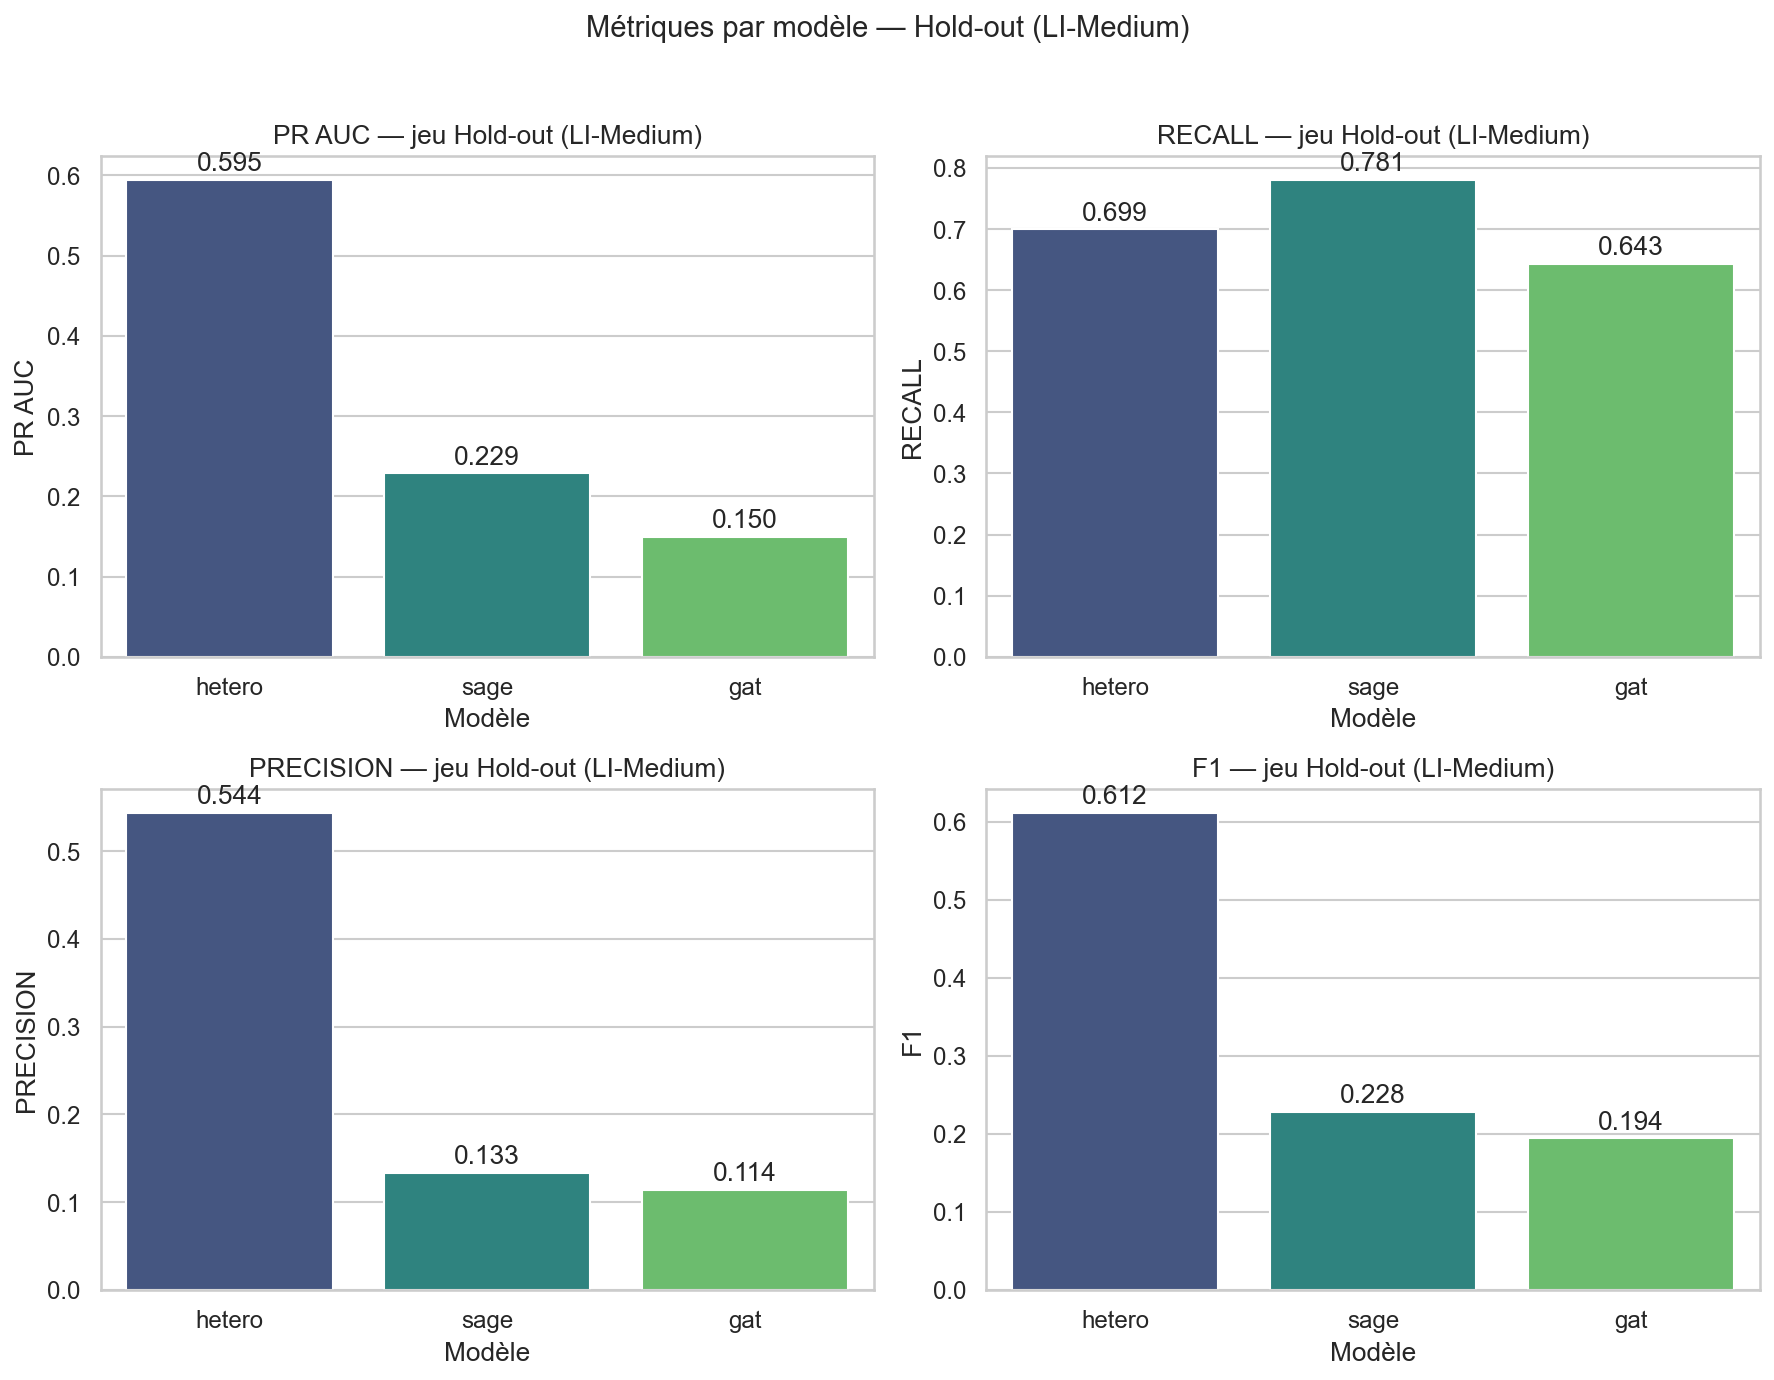

### holdout_pr_auc_bars.png

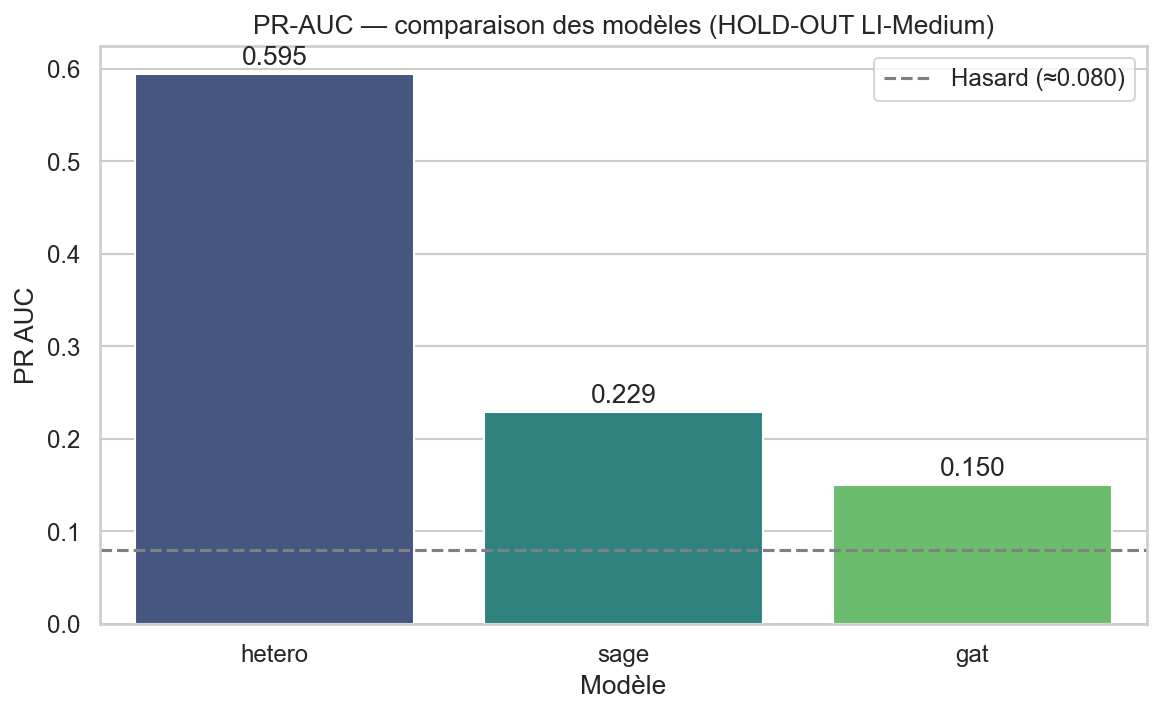

### holdout_architecture_comparison.png

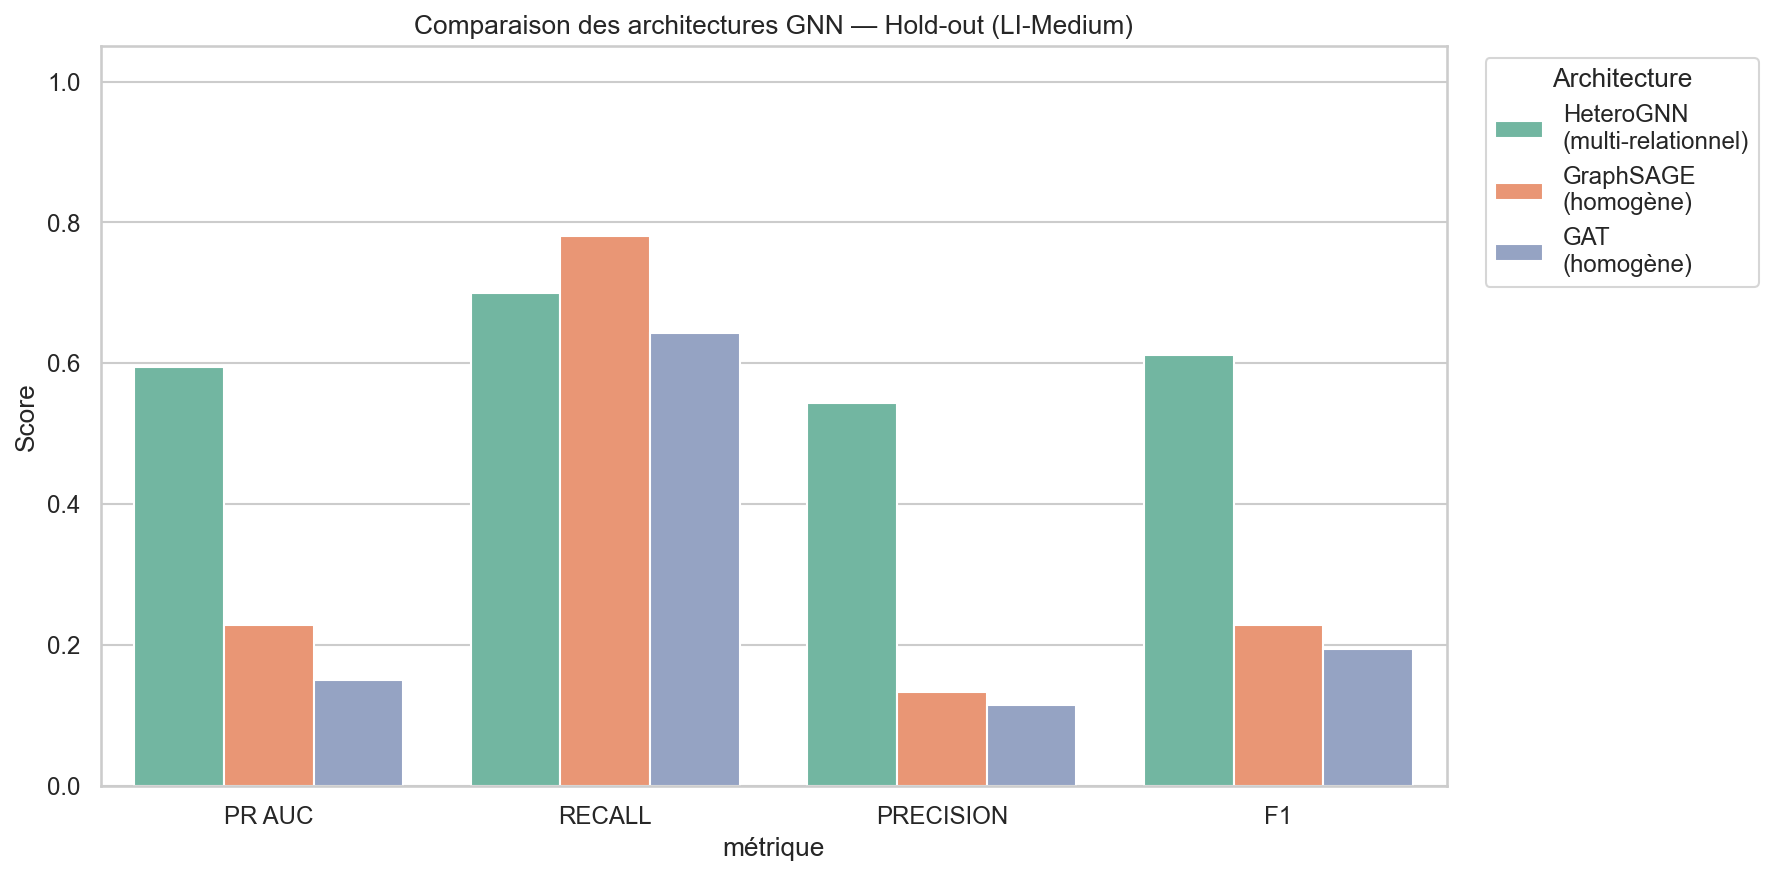

### holdout_architecture_radar.png

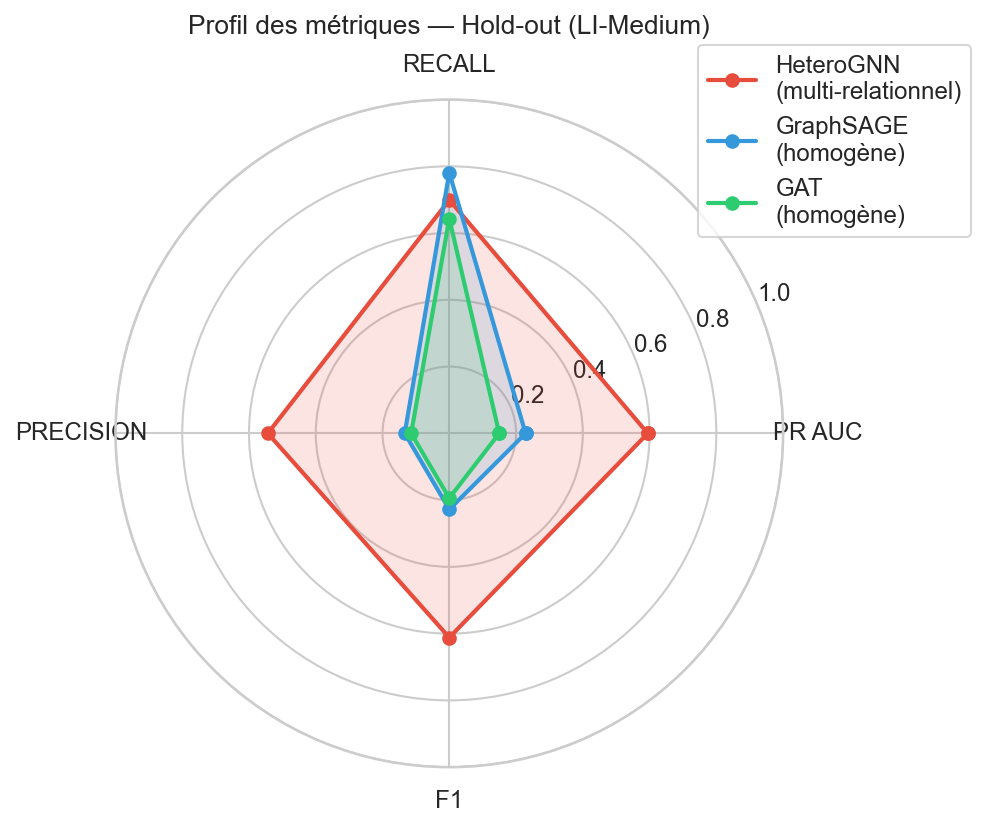

### holdout_pr_curves_all_models.png

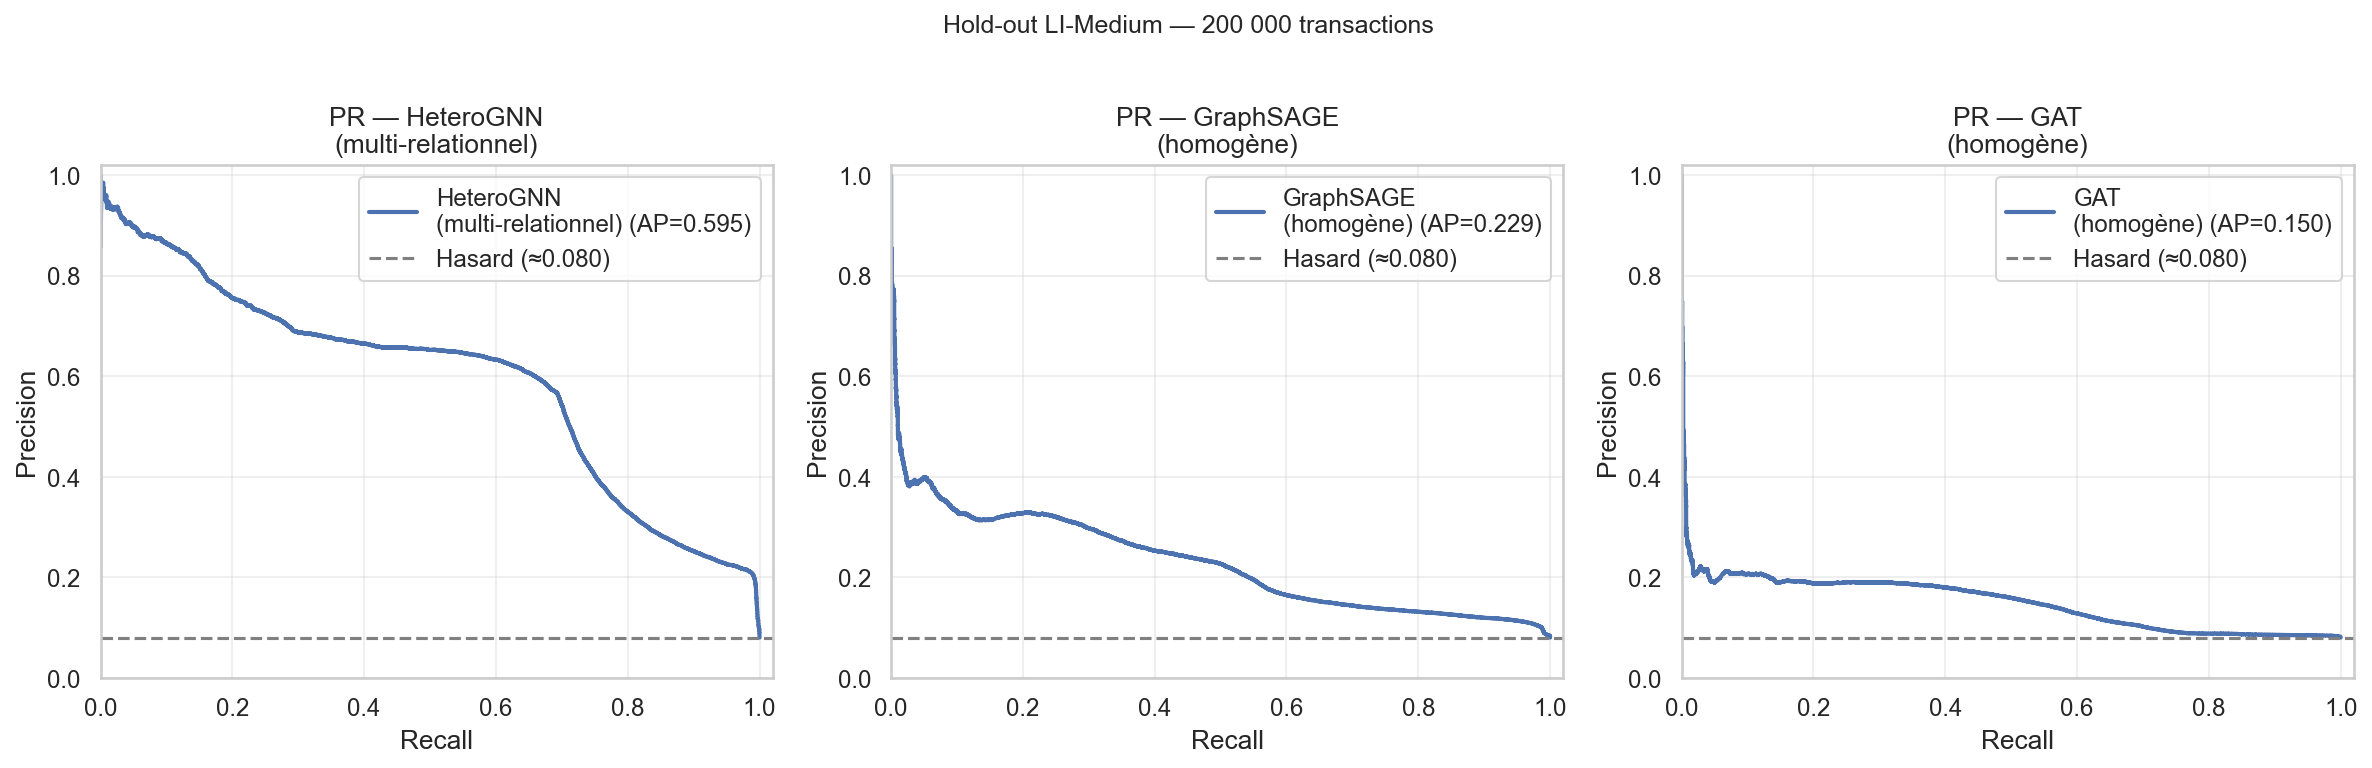

### holdout_confusion_matrices_all_models.png

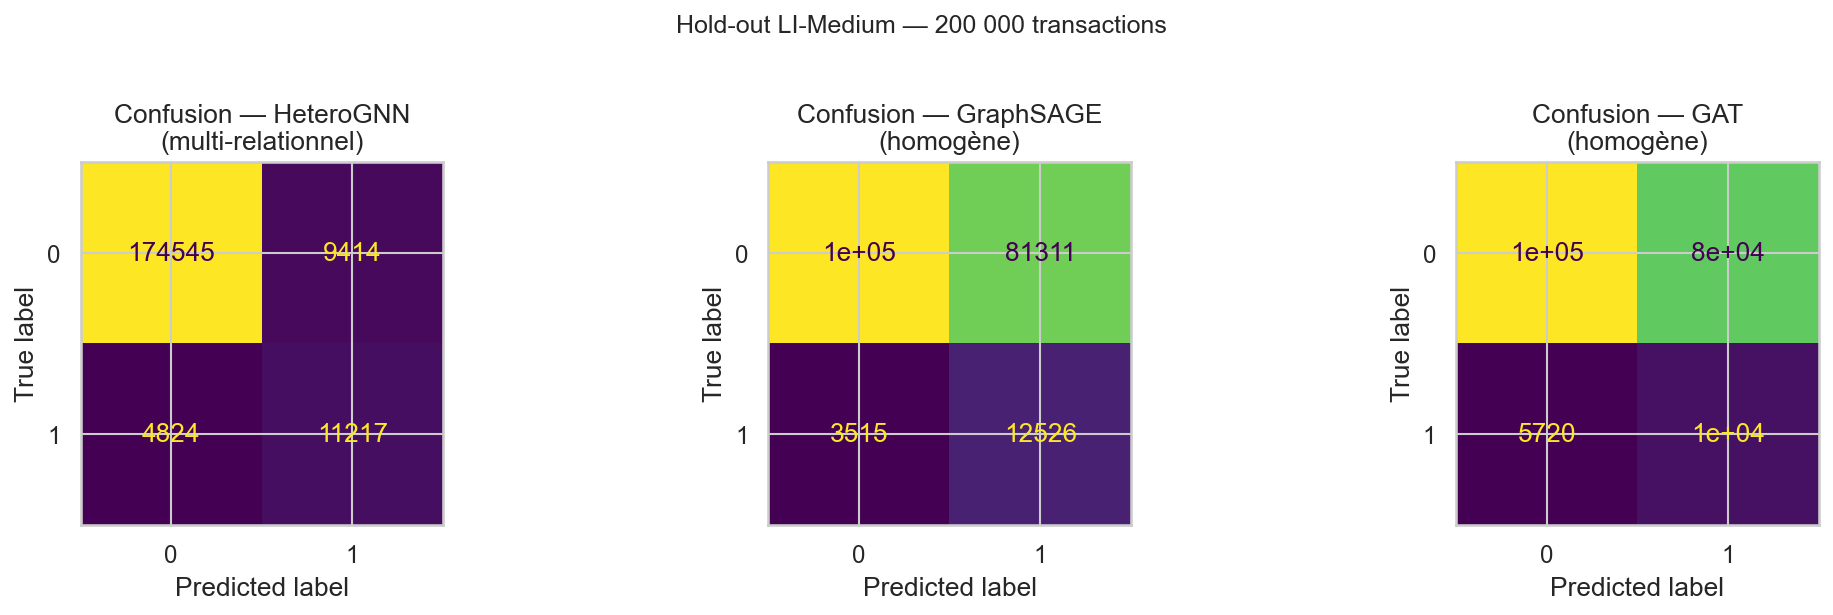

### holdout_score_distributions_all_models.png

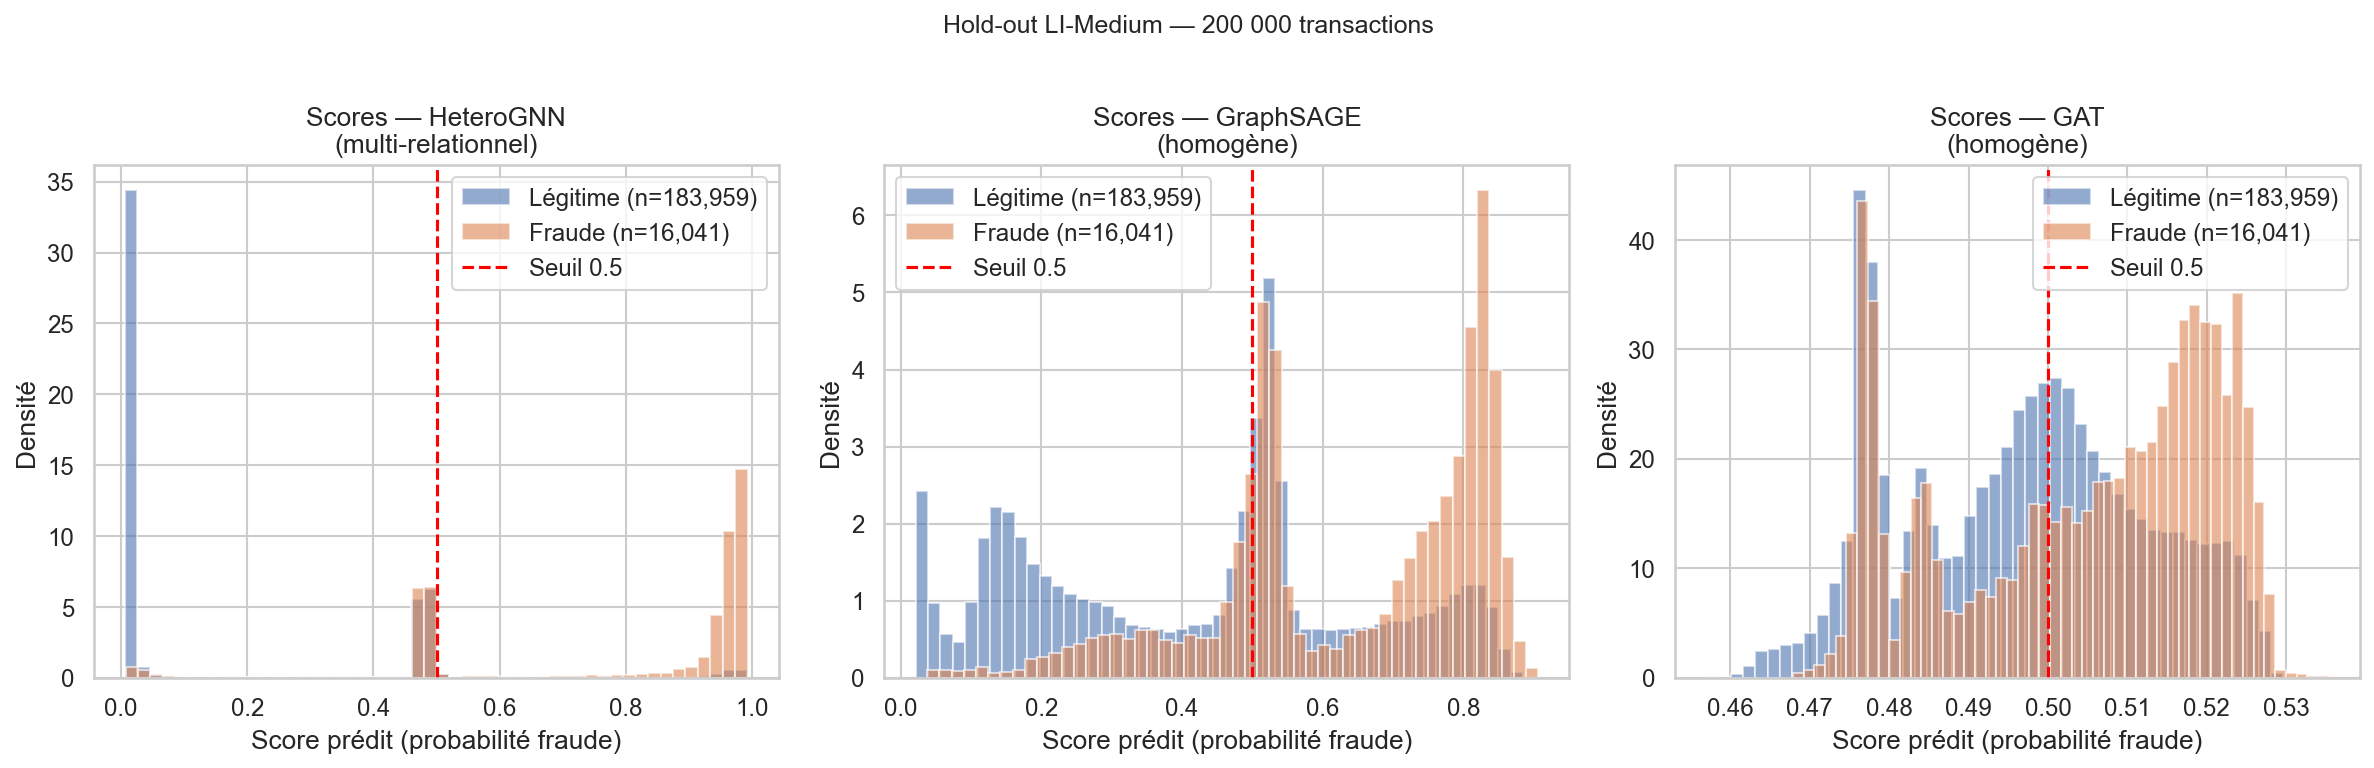

### holdout_pr_curve_hetero.png

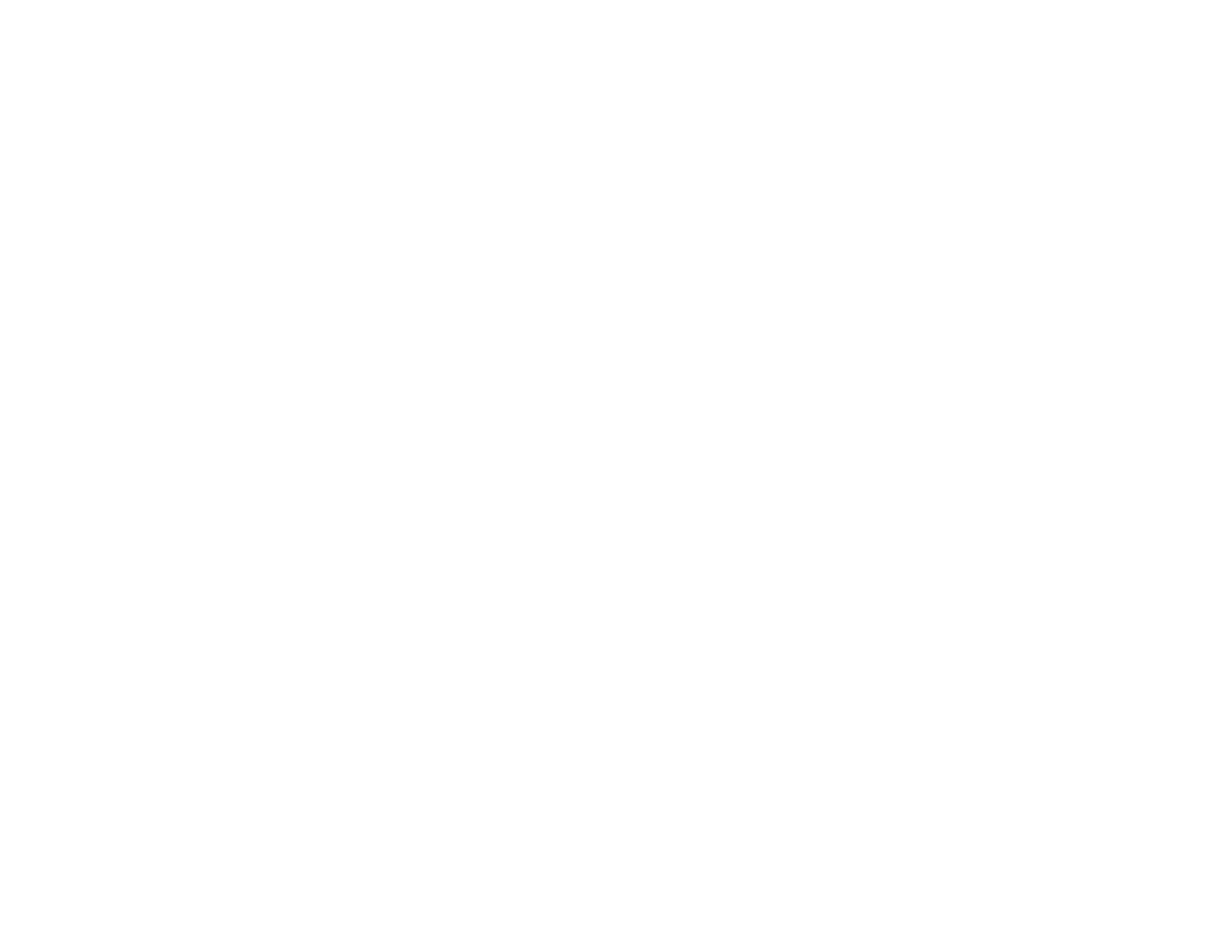

### holdout_confusion_matrix_hetero.png

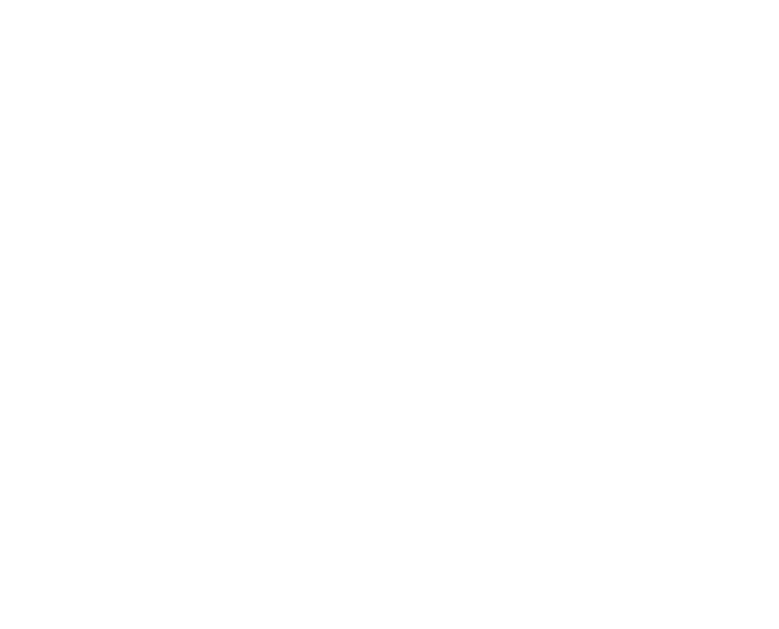

### holdout_score_distribution_hetero.png

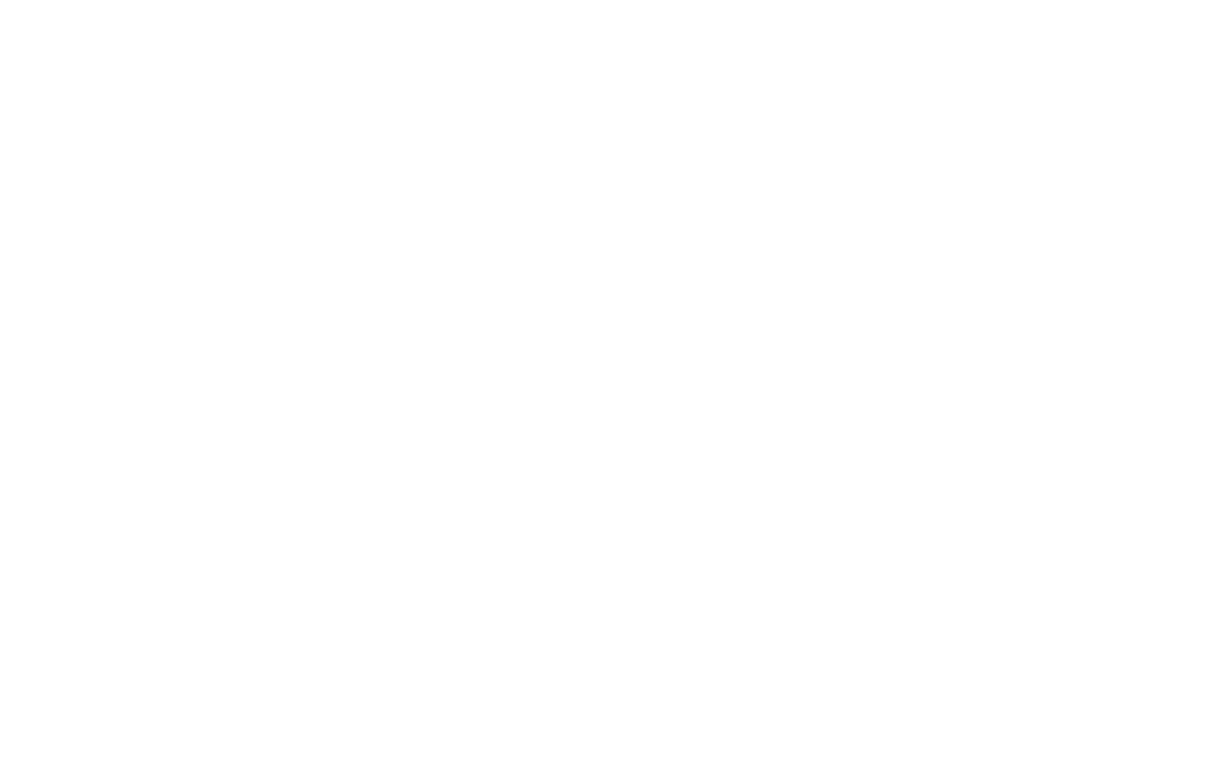

### holdout_train_vs_holdout_pr_auc.png

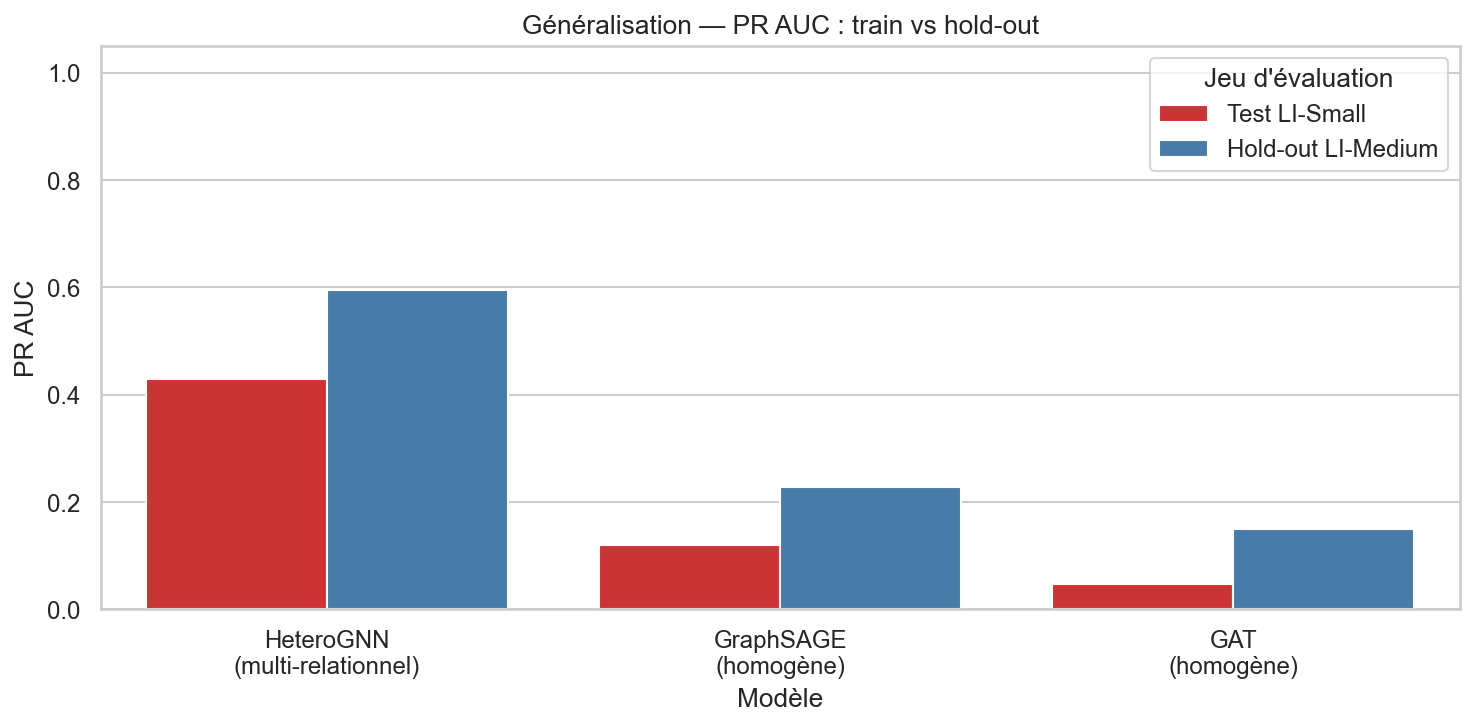

### holdout_train_convergence_reference.png

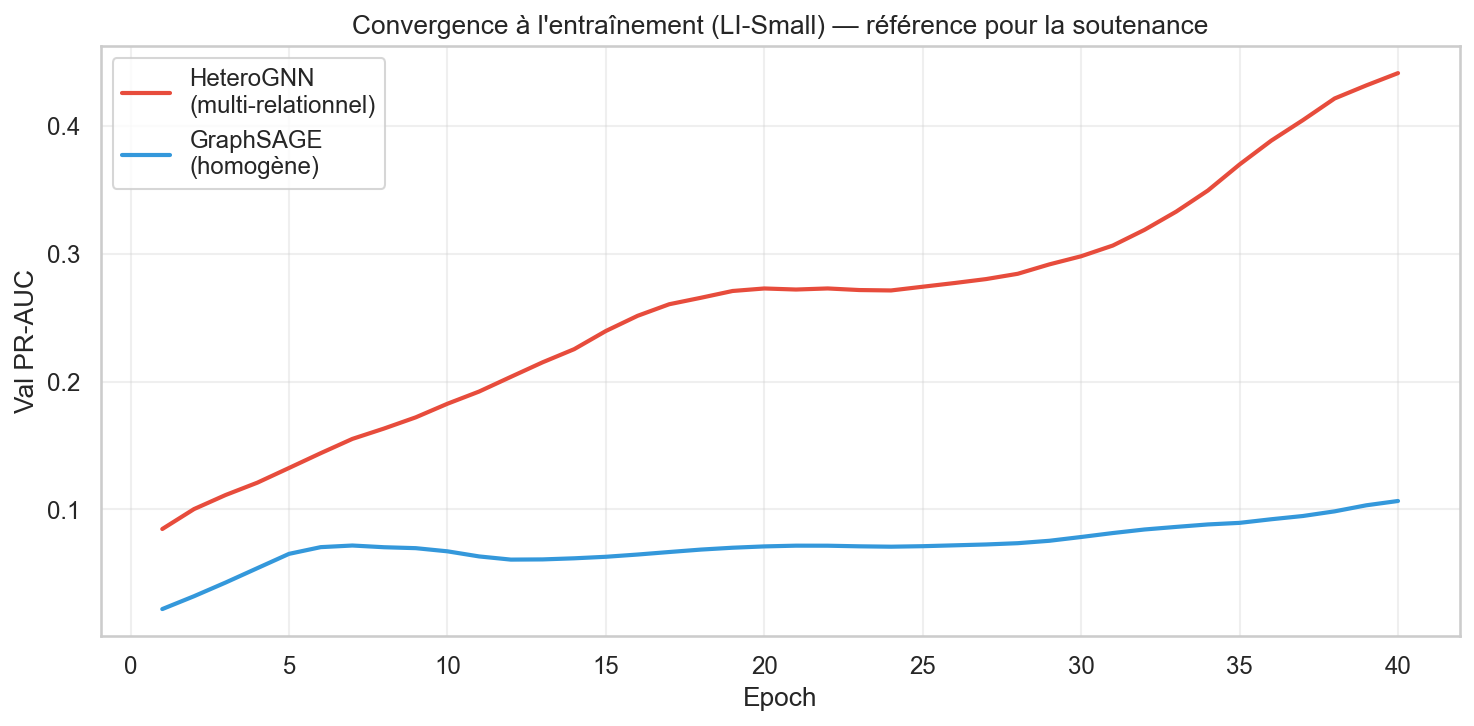

In [4]:
FIGURES = [
    "holdout_metrics_grid.png",
    "holdout_pr_auc_bars.png",
    "holdout_architecture_comparison.png",
    "holdout_architecture_radar.png",
    "holdout_pr_curves_all_models.png",
    "holdout_confusion_matrices_all_models.png",
    "holdout_score_distributions_all_models.png",
    "holdout_pr_curve_hetero.png",
    "holdout_confusion_matrix_hetero.png",
    "holdout_score_distribution_hetero.png",
    "holdout_train_vs_holdout_pr_auc.png",
    "holdout_train_convergence_reference.png",
]
for name in FIGURES:
    p = RESULTS_DIR / name
    if p.exists():
        display(Markdown(f"### {name}"))
        display(Image(filename=str(p)))
    else:
        print("Manquant :", name)